# AIP304 Coursework 2 — Option 1: plant-disease recognition in the wild

**Task.** Predict the host–disease class (43 classes, 9 hosts) of a single RGB photograph from the PlantSeg v7
subset defined in the task sheet. Closed-set classification; primary metric **macro-F1**.

**Team.** _Name (ID)_ · _Name (ID)_ · _Name (ID)_ — **Option 1**. AI-use disclosure and contribution statement are in the report.

**Headline result (test, evaluated once after a validation-only freeze).**
3-seed ensemble of ImageNet-pretrained ConvNeXt-Tiny, fine-tuned with augmentation: **macro-F1 0.805**,
accuracy 0.842, balanced accuracy 0.800 — against 0.003 for the majority-class predictor and 0.548 for a frozen ResNet-18.

### How this notebook runs
| `MODE` | what happens | time (Colab T4) |
|---|---|---|
| `"demo"` (default) | downloads + checks the data, rebuilds and verifies the manifest/audit, regenerates every table and figure from the committed run records (`results/runs/`: per-epoch history and val/test logits of all 66 runs), downloads the 3 final checkpoints from Hugging Face and runs inference | ~10–15 min (1.06 GB download) |
| `"full"` | additionally **retrains** the planned comparisons E0–E3 and the final configuration (5 configs × 3 seeds) into `outputs/rerun/` and compares them with the committed numbers; `RUN_FULL_SWEEP=True` retrains all 22 configurations and re-runs the selection | 25 min on an L4 (measured); ~1–1.5 h on a T4 (estimate); full sweep ~4 h on an L4 |

**The saved outputs in this file come from a `MODE="full"` execution** on one NVIDIA L4: the training log is in
Section 5, and the 15 retrained runs reproduce the committed validation and test numbers exactly (table in Section 8).
The original sweep ran up to 4 runs at once on the same GPU, so times recorded in `run.json` are under that sharing.

In [1]:
import os
MODE = os.environ.get("CW2_MODE", "demo")   # "demo" | "full" (default demo)
RUN_FULL_SWEEP = False   # only used when MODE == "full"
REPO_URL = "https://github.com/Alex-jjh/plantseg-aip.git"   # public repo: this notebook, cw2/ and results/

import os, sys, subprocess, pathlib
IN_COLAB = "google.colab" in sys.modules
REPO = next((p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "cw2").is_dir()), None)
if REPO is None:  # fresh Colab/Kaggle session: fetch the code + committed results
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "plantseg-aip"], check=True)
    REPO = pathlib.Path("plantseg-aip").resolve()
if IN_COLAB or os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)
sys.path.insert(0, str(REPO))
print("repo:", REPO)

repo: /home/alexjia/.workspace/plantseg-aip


In [2]:
import json, platform, time
import numpy as np, pandas as pd, torch, torchvision, sklearn, matplotlib, PIL
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from cw2.paths import Paths
from cw2 import data as D, experiments as X, report as R, viz, inference as I
from cw2.metrics import evaluate
from cw2.train import Config, batch_aug, normalise, MEAN, STD

P = Paths(REPO)
viz.style()
pd.set_option("display.precision", 4); pd.set_option("display.max_rows", 60); pd.set_option("display.width", 160)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEL = json.load(open(P.summary / "selection.json"))          # frozen, validation-only choice (Section 7)
print(f"python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__} | "
      f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__} | Pillow {PIL.__version__}")
print("device:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU", "| MODE:", MODE)

python 3.12.15 | torch 2.15.0+cu132 | torchvision 0.29.2+cu132 | scikit-learn 1.9.1 | pandas 3.1.1 | matplotlib 3.11.2 | Pillow 13.0.0
device: NVIDIA L4 | MODE: full


## 1. Data access and checksum

PlantSeg **v7** (Wei et al., 2025; Zenodo record 17719108, released 25 Nov 2025). The archive is downloaded from the
versioned record and verified against its published MD5 before use; no other release is mixed in.

In [3]:
t0 = time.time()
ROOT = D.download_plantseg(P.raw_zip, P.data_root.parent)
print(f"ready in {time.time() - t0:.0f}s")

plantseg.zip md5 OK (9358a66dff88cdd15c4fe009763c40a3); data root /home/alexjia/.workspace/plantseg-aip/data/plantseg/plantseg
ready in 1s


## 2. Subset, manifest and audit

**Subset.** Images whose host is one of apple, banana, citrus, corn, potato, soybean, tomato, wheat, zucchini. Each
supplied host–disease `Disease` label is one class (e.g. potato late blight ≠ tomato late blight); class ids follow
alphabetical order of the labels. The supplied partition (`Split` = Training / Validation / Test, ≈70/10/20) is kept.
Labels come only from the metadata — file names (which contain the class) are never used as inputs.

**Audit rule (fixed before any modelling, applied once to all methods).**
1. Unreadable files are dropped (none found).
2. *Duplicates* = byte-identical files **or** perceptual-hash (pHash) Hamming distance ≤ 4. A visual check of sampled
   pairs at distances 2 and 4 showed the same photo re-cropped, re-coloured or watermarked, so these count as duplicates.
   Pairs are merged into groups (connected components).
3. In a group whose members share one label, one copy is kept — the one in the latest partition (test > val > train) —
   so a photo never appears in two partitions. A group whose members carry **different labels** is dropped entirely
   (the same photo cannot be two classes; keeping either label would be arbitrary).

The cell below rebuilds the manifest from the raw metadata and checks it is identical to the committed one that every
experiment used (`results/data/manifest.csv`).

In [4]:
t0 = time.time()
rebuilt_dir = P.outputs / "rebuilt_data"
man_all, excl, audit = D.prepare_manifest(ROOT, rebuilt_dir)
committed = pd.read_csv(P.data_results / "manifest.csv")
cols = ["image_id", "path", "class_name", "class_id", "partition", "excluded"]
assert man_all[cols].reset_index(drop=True).equals(committed[cols]), "rebuilt manifest differs from the committed one"
print(f"audit {time.time() - t0:.0f}s - rebuilt manifest identical to results/data/manifest.csv")

part = man_all.set_index("image_id")["partition"]; cls = man_all.set_index("image_id")["class_name"]
groups = audit["duplicate_groups"]
summary = pd.Series({
    "images in subset": len(man_all), "classes": man_all.class_id.nunique(), "unreadable files": len(audit["unreadable"]),
    "byte-identical groups": len(audit["exact_groups"]), "pHash<=4 pairs": len(audit["near_pairs"]),
    "duplicate groups (merged)": len(groups), "  ...spanning partitions": sum(part[g].nunique() > 1 for g in groups),
    "  ...with conflicting labels": sum(cls[g].nunique() > 1 for g in groups), "images excluded": len(excl)})
display(summary.to_frame("count"))
display(excl.reason.str.split(" of ").str[0].value_counts().to_frame("excluded images"))
MAN, CLASSES = D.load_kept(P.data_results)
counts = pd.crosstab(MAN.class_name, MAN.partition)[["train", "val", "test"]]
display(pd.crosstab(man_all.excluded.map({False: "kept", True: "excluded"}), man_all.partition)[["train", "val", "test"]])
print("smallest classes (kept):"); display(counts.assign(total=counts.sum(axis=1)).sort_values("total").head(6))

audit 36s - rebuilt manifest identical to results/data/manifest.csv


,count
images in subset,4349
classes,43
unreadable files,0
byte-identical groups,161
pHash<=4 pairs,419
duplicate groups (merged),327
...spanning partitions,162
...with conflicting labels,54
images excluded,424


,excluded images
reason,
duplicate,312
duplicate with conflicting labels,112


partition,train,val,test
excluded,,,
excluded,348,36,40
kept,2659,439,827


smallest classes (kept):


partition,train,val,test,total
class_name,,,,
banana cordana leaf spot,17,2,8,27
banana cigar end rot,19,2,9,30
zucchini downy mildew,23,3,5,31
tomato mosaic virus,27,4,7,38
soybean brown spot,31,1,10,42
soybean bacterial blight,29,4,13,46


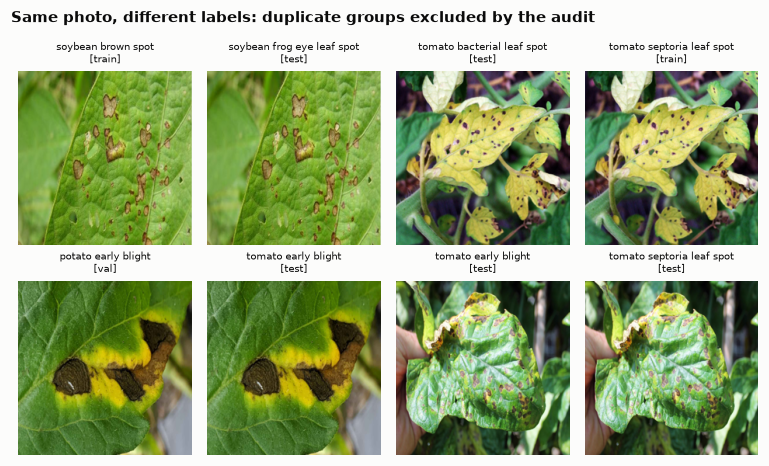

In [5]:
R.fig_conflicts(P); plt.show()

**Remaining leakage risk (limitation).** pHash catches re-encoded, re-cropped and watermarked copies of one photo, but
not different photos of the same plant or scene taken seconds apart; such near-duplicates may still span partitions.
The conflicting-label groups (54 groups, 112 images) also show that the web-sourced labels contain some noise —
e.g. the identical leaf labelled *potato* and *tomato early blight*.

## 3. Exploring the data

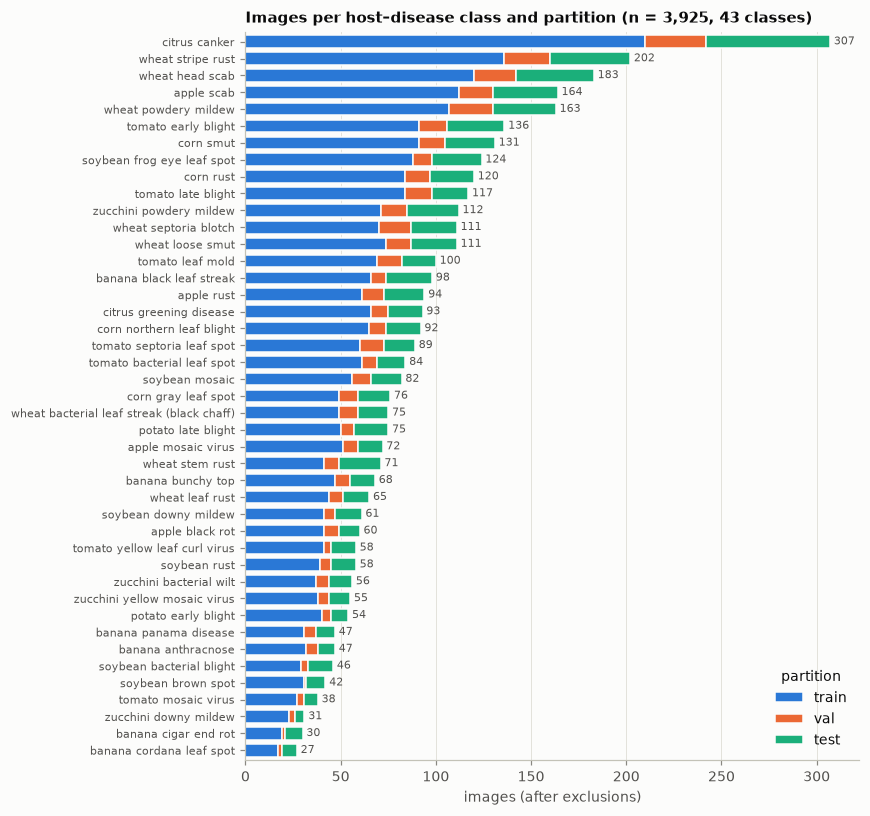

training images per class: max 210 (citrus canker), min 17 (banana cordana leaf spot), ratio 12.4x; 3 classes have <= 2 validation images


In [6]:
R.fig_class_counts(P); plt.show()
tr = counts["train"]
print(f"training images per class: max {tr.max()} ({tr.idxmax()}), min {tr.min()} ({tr.idxmin()}), ratio {tr.max()/tr.min():.1f}x; "
      f"{(counts['val'] <= 2).sum()} classes have <= 2 validation images")

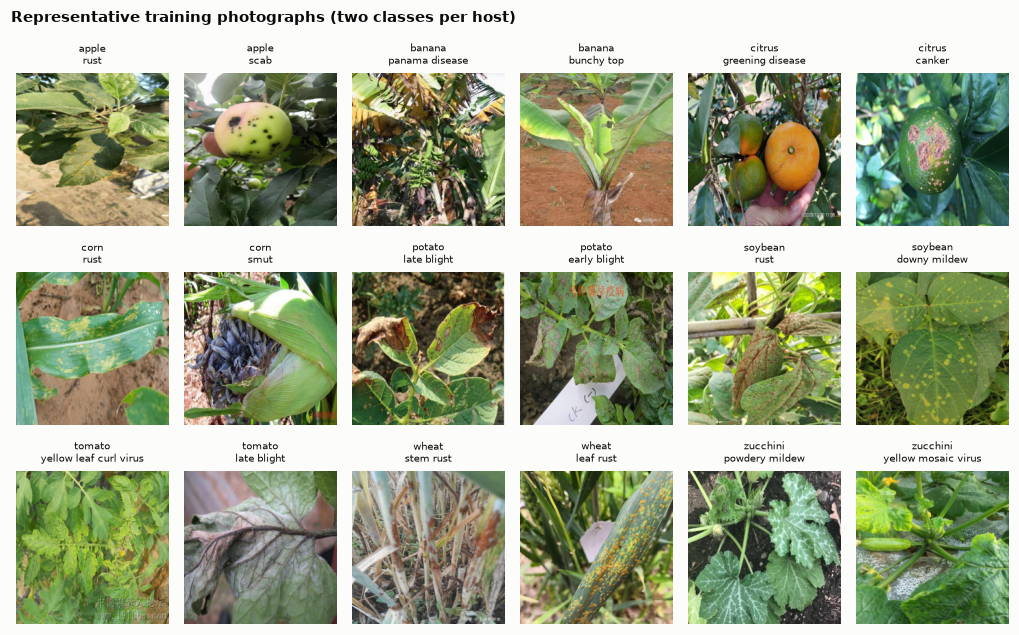

In [7]:
R.fig_samples(P); plt.show()

**Why this is hard.**
- **Similar symptoms across classes**, often on the same host: wheat leaf / stripe / stem rust, tomato septoria vs
  bacterial leaf spot, and the *same disease on different hosts* (early blight on potato vs tomato), which counts as
  different classes here.
- **Small lesions and whole-plant shots**: many photos show a field or canopy where the symptom covers a few percent of
  the pixels; others are close-ups. Resizing must not throw the lesion away.
- **Uncontrolled backgrounds**: soil, hands, sky, labels, text overlays and watermarks from the web sources.
- **Imbalance**: 210 training images for citrus canker vs 17 for banana cordana leaf spot (12×); the validation set is
  small (439 images), so validation macro-F1 is noisy — one image can move a rare class's F1 by 0.3.

## 4. Method

**Protocol.** Training images fit the parameters (and class weights where used); validation chooses architecture,
augmentation, hyperparameters and the checkpoint; test is used once, after the choice is frozen (Section 7).

**Preprocessing.** Each photo is resized *whole* to a square (256×256 for 224-pixel input) — no centre crop, so lesions
near the border are not cut off; the price is an aspect-ratio distortion, which the CNN tolerates. Then it is resized to
the input size and normalised with the ImageNet mean/std documented with the torchvision weights (no statistics are
fitted on our data). Validation/test transforms are deterministic; evaluation runs in `eval()` mode under `no_grad`.

**Model and training.** ImageNet-1k weights from torchvision (never PlantSeg/PlantWild checkpoints); the last linear
layer is replaced by a 43-way classifier. Cross-entropy loss; AdamW (weight decay 1e-4) with learning rate 1e-3 for the
new layer and a smaller rate for the pretrained backbone (default 1e-4), one-cycle schedule (10% warm-up); batch 32;
30 epochs; mixed precision. **Checkpoint rule:** the epoch with the highest validation macro-F1.

**Augmentation (training only).** One random affine per image on the GPU: a random-resized crop keeping 60–100% of the
image area (so small lesions are rarely cropped out), horizontal and vertical flips, rotation ±20°, and brightness and
contrast in [0.8, 1.2]. Hue and saturation are **not** changed because colour (yellowing, rust, chlorosis) is diagnostic.

Config(name='defaults', finetune=True, class_weights=False, augment=False, epochs=30, batch_size=32, lr_head=0.001, lr_backbone=0.0001, weight_decay=0.0001, label_smoothing=0.0, arch='resnet18', input_size=224, seed=0)


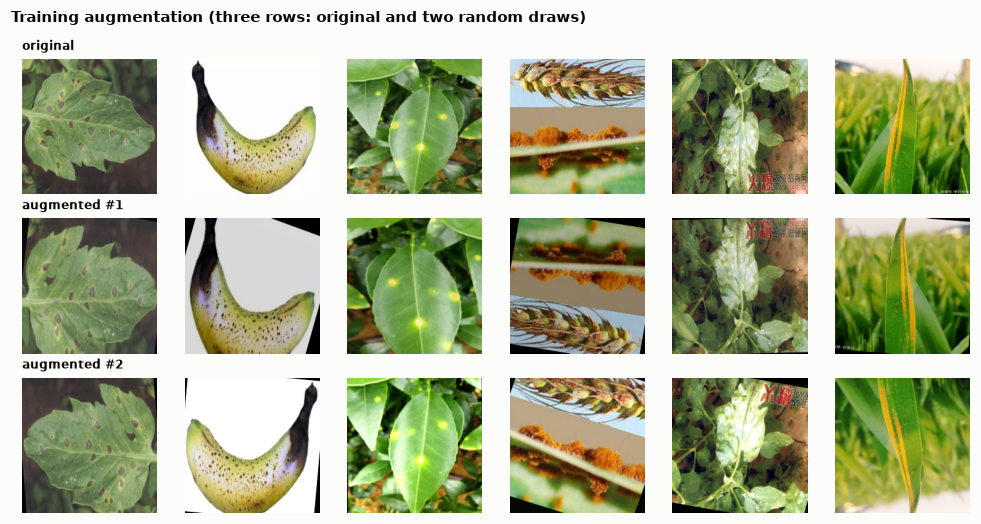

In [8]:
print(Config("defaults"))
train_rows = MAN[MAN.partition == "train"].sample(6, random_state=1)
imgs = I.load_images([P.data_root / p for p in train_rows.path], 256).to(DEVICE).float() / 255
g = torch.Generator(device=DEVICE).manual_seed(0)
aug = [batch_aug(imgs, 224, g) for _ in range(2)]
fig, axes = plt.subplots(3, 6, figsize=(9, 4.8))
for j in range(6):
    for i, (x, t) in enumerate([(imgs, "original"), (aug[0], "augmented #1"), (aug[1], "augmented #2")]):
        axes[i, j].imshow(x[j].permute(1, 2, 0).cpu().numpy()); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(t, fontsize=8, loc="left")
fig.suptitle("Training augmentation (three rows: original and two random draws)", x=0.01, ha="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

**Metrics (Section 3.2 of the task sheet).** For each class *c*: precision TP/(TP+FP), recall TP/(TP+FN),
F1 = 2TP/(2TP+FP+FN). **Macro-F1** (primary) is the unweighted mean of the 43 per-class F1 values in a fixed class
order (alphabetical); **balanced accuracy** is the mean per-class recall; **top-1 accuracy** is correct/evaluated.
*Undefined values:* a class that is never predicted has precision 0/0, which is set to 0 (and so is its F1). Every class
has validation and test support after the audit (asserted in `cw2/metrics.py`), so recall is always defined.

## 5. Baselines and controlled changes

The required comparison changes **one factor at a time**, each with 3 seeds (0, 1, 2):

| run | change vs previous | purpose |
|---|---|---|
| majority class | — | floor: always predict the most frequent training class |
| **E0** frozen ResNet-18 | — | basic CNN: pretrained features fixed, train only the classifier |
| **E1** fine-tune | E0 + train all layers | controlled change 1 |
| **E2** + class weights | E1 + inverse-frequency weighted loss | controlled change 2 |
| **E3** + augmentation | E1 + augmentation | controlled change 3 |

In [9]:
RUNS = P.runs if MODE == "demo" else P.outputs / "rerun" / "runs"
if MODE == "full":
    spec = X.load_spec(P)
    if not RUN_FULL_SWEEP:
        spec = {k: v for k, v in spec.items() if k in X.COMPARISONS + [SEL["final_config"]]}
    print(f"training {len(spec)} configs x 3 seeds into {RUNS} ...")
    X.run_sweep(spec, P, RUNS, DEVICE, ckpt_dir=P.outputs / "rerun" / "checkpoints")

val = X.summarize_val(P.runs)
labels = R.config_labels(P)
tab = val.loc[X.COMPARISONS, ["val_macro_f1", "sd", "val_accuracy", "val_balanced_accuracy", "best_epoch"]]
tab.insert(0, "config", [labels[n] for n in tab.index])
display(Markdown("**Validation, 3-seed mean (sd = macro-F1 standard deviation over seeds)**")); display(tab)

training 5 configs x 3 seeds into /home/alexjia/.workspace/plantseg-aip/outputs/rerun/runs ...


E0_frozen s0: val macro-F1 0.5348 (epoch 27, 27s)


E0_frozen s1: val macro-F1 0.5284 (epoch 22, 27s)


E0_frozen s2: val macro-F1 0.5308 (epoch 21, 27s)


E1_finetune s0: val macro-F1 0.6625 (epoch 9, 72s)


E1_finetune s1: val macro-F1 0.6598 (epoch 17, 72s)


... (8 outputs left out)

S3_cnxt_lrb2e-4 s1: val macro-F1 0.7994 (epoch 20, 244s)


S3_cnxt_lrb2e-4 s2: val macro-F1 0.7938 (epoch 14, 244s)


**Validation, 3-seed mean (sd = macro-F1 standard deviation over seeds)**

,config,val_macro_f1,sd,val_accuracy,val_balanced_accuracy,best_epoch
name,,,,,,
E0_frozen,resnet18 · frozen,0.5313,0.0032,0.6173,0.5274,23.3333
E1_finetune,resnet18 · fine-tune,0.6537,0.0129,0.7213,0.6566,13.0000
E2_finetune_cw,resnet18 · fine-tune · class-weighted,0.6553,0.0094,0.7236,0.6589,8.6667
E3_finetune_aug,resnet18 · fine-tune · aug,0.7332,0.0242,0.7813,0.7375,19.6667


Fine-tuning the whole network is the largest single gain (+0.12 validation macro-F1 over the frozen backbone).
Class weighting changes nothing measurable (0.654 → 0.655, well inside the seed spread), while augmentation adds
about +0.08 — the model overfits the 2,659 training photos without it (training loss → 0 within ~10 epochs).

## 6. Improving the CNN: validation search

Starting from E3, the search changed one factor at a time (stage 1), then combined the helpful ones (stage 2) and
refined the best backbone (stage 3). Every configuration ran with 3 seeds and identical data, preprocessing, epoch
budget and checkpoint rule:

- **stage 1** (on E3): class weights; backbone learning rate 3e-5 / 3e-4; 50 epochs; label smoothing 0.1; 280-pixel
  input; backbones ResNet-50, EfficientNet-B0, ConvNeXt-Tiny, MobileNetV3-Large.
- **stage 2**: ConvNeXt-Tiny + 280 px / + label smoothing; ResNet-50 + 280 px; ResNet-18 + 280 px + label smoothing; ResNet-18 + 336 px.
- **stage 3**: ConvNeXt-Small; ConvNeXt-Tiny with backbone learning rate 5e-5 / 2e-4.

Two stage-2 combinations were **pruned on validation evidence before they finished** (`sweeps/pruned.json`): ConvNeXt-Tiny
was worse at 280 px than at 224 px, and ResNet-50 at 280 px was clearly below ConvNeXt-Tiny at higher cost.

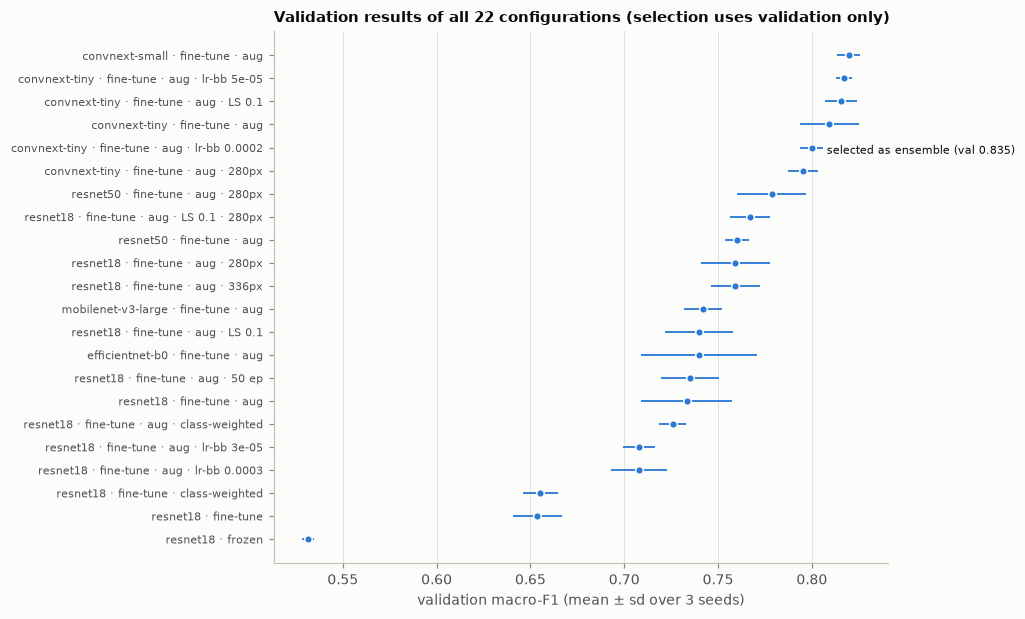

,config,val_macro_f1,sd,val_accuracy,best_epoch,train_seconds
name,,,,,,
S3_cnxs,convnext-small · fine-tune · aug,0.8196,0.0059,0.8588,23.6667,1602.3333
S3_cnxt_lrb5e-5,convnext-tiny · fine-tune · aug · lr-bb 5e-05,0.8171,0.0042,0.8519,12.6667,1036.0000
S2_cnxt_ls0.1,convnext-tiny · fine-tune · aug · LS 0.1,0.8157,0.0084,0.8550,17.0000,1063.6667
S1_aug_convnext_t,convnext-tiny · fine-tune · aug,0.8093,0.0156,0.8481,19.6667,1008.6667
S3_cnxt_lrb2e-4,convnext-tiny · fine-tune · aug · lr-bb 0.0002,0.7998,0.0062,0.8413,14.6667,804.3333
S2_cnxt_280,convnext-tiny · fine-tune · aug · 280px,0.7953,0.0082,0.8466,21.3333,1595.3333
S2_r50_280,resnet50 · fine-tune · aug · 280px,0.7785,0.0182,0.8276,20.6667,1543.6667
S2_r18_280_ls0.1,resnet18 · fine-tune · aug · LS 0.1 · 280px,0.7670,0.0109,0.8140,25.0000,548.0000
S1_aug_resnet50,resnet50 · fine-tune · aug,0.7603,0.0064,0.8155,23.0000,881.6667


pruned: {'S2_cnxt_280_ls0.1': 'pruned on validation before running: convnext_tiny at 280px (0.795) was below 224px (0.809), so adding label smoothing at 280px was not expected to beat the 224px configs; 2 of 3 seeds were stopped early and discarded', 'S2_r50_280_ls0.1': 'pruned on validation before running: resnet50 configurations (<=0.78) were clearly below convnext_tiny (~0.81) at higher cost'}


In [10]:
R.fig_sweep(P, SEL); plt.show()
v = val[["val_macro_f1", "sd", "val_accuracy", "best_epoch", "train_seconds"]].copy()
v.insert(0, "config", [labels[n] for n in v.index]); display(v)
print("pruned:", json.load(open(P.sweep("pruned"))))

**What the search shows.** The backbone matters most: ConvNeXt (≈0.80–0.82) > ResNet-50 (0.76–0.78) > ResNet-18
(0.73–0.77) ≈ MobileNetV3 / EfficientNet-B0 (≈0.74). Higher resolution helps the ResNets (+0.02–0.03) but not
ConvNeXt. Label smoothing, longer training and class weighting give at most small, seed-level differences; moving the
ResNet-18 backbone learning rate away from 1e-4 hurts in both directions.

## 7. Model selection — validation only, then frozen

**Rule (fixed before the results were seen).** Candidates are every configuration (3-seed mean validation macro-F1) and
the 3-seed ensemble (mean of softmax probabilities) of the five best configurations; the highest validation macro-F1
wins. The choice was written to `results/summary/selection.json` before any test metric was computed.

In [11]:
if MODE == "full" and RUN_FULL_SWEEP:
    SEL_RERUN = X.select_final(P, RUNS, P.outputs / "rerun" / "selection.json")
    print("re-run selection:", SEL_RERUN["final_config"], SEL_RERUN["final_kind"])
cand = pd.DataFrame(SEL["candidates"]).head(10)
cand.insert(1, "config", [labels[n] for n in cand.candidate])
display(cand.drop(columns="candidate"))
print({k: SEL[k] for k in ("final_config", "final_kind", "final_val_macro_f1", "frozen_at")})

,config,kind,val_macro_f1,sd
0,convnext-tiny · fine-tune · aug · lr-bb 0.0002,ensemble (3 seeds),0.8350,NaN
1,convnext-tiny · fine-tune · aug,ensemble (3 seeds),0.8334,NaN
2,convnext-small · fine-tune · aug,ensemble (3 seeds),0.8209,NaN
3,convnext-small · fine-tune · aug,single (3-seed mean),0.8196,0.0059
4,convnext-tiny · fine-tune · aug · lr-bb 5e-05,single (3-seed mean),0.8171,0.0042
5,convnext-tiny · fine-tune · aug · LS 0.1,single (3-seed mean),0.8157,0.0084
6,convnext-tiny · fine-tune · aug,single (3-seed mean),0.8093,0.0156
7,convnext-tiny · fine-tune · aug · lr-bb 5e-05,ensemble (3 seeds),0.8084,NaN
8,convnext-tiny · fine-tune · aug · LS 0.1,ensemble (3 seeds),0.8023,NaN
9,convnext-tiny · fine-tune · aug · lr-bb 0.0002,single (3-seed mean),0.7998,0.0062


{'final_config': 'S3_cnxt_lrb2e-4', 'final_kind': 'ensemble (3 seeds)', 'final_val_macro_f1': 0.8350307683241964, 'frozen_at': '2026-11-21T14:16:06.443990+00:00'}


The winner is the ensemble of three ConvNeXt-Tiny models (backbone learning rate 2e-4). The top candidates are within
0.02 of each other, which is about the size of a single image changing class in the three rarest validation classes;
the ordering among them is therefore not meaningful — Section 9 shows they are equally good on test. The rule was kept
rather than overridden after seeing these numbers.

### Training curves of the final configuration

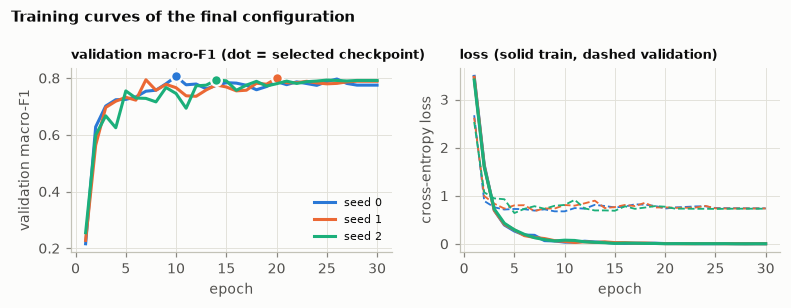

In [12]:
R.fig_curves(P, SEL); plt.show()

Training loss reaches ~0 within 10 epochs while validation loss flattens around 0.75: the model memorises the training
photos, and augmentation plus checkpoint selection by validation macro-F1 control the damage. The selected epochs
(dots) are 10, 20 and 14.

## 8. Test results (evaluated once, after the freeze)

,system,macro_f1,accuracy,balanced_accuracy,macro_f1_sd,accuracy_sd,balanced_accuracy_sd
0,Majority class,0.0034,0.0786,0.0233,NaN,NaN,NaN
1,E0_frozen (3 seeds),0.5476,0.6074,0.5407,0.0093,0.0067,0.0088
2,E1_finetune (3 seeds),0.6531,0.7001,0.6437,0.0139,0.0094,0.0129
3,E2_finetune_cw (3 seeds),0.6622,0.7106,0.6575,0.0075,0.0046,0.0112
4,E3_finetune_aug (3 seeds),0.7089,0.7505,0.7024,0.0049,0.0071,0.0086
5,S3_cnxt_lrb2e-4 (3 seeds),0.7963,0.8319,0.7909,0.0049,0.0048,0.0044
6,S3_cnxt_lrb2e-4 ensemble (final),0.8048,0.8416,0.7996,NaN,NaN,NaN


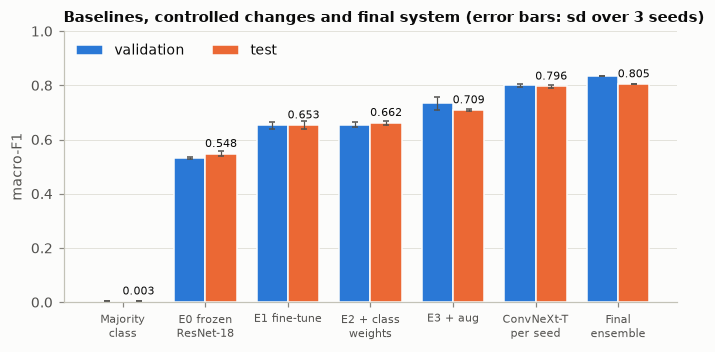

**Reproduction check: retrained in this session vs committed**

,macro_f1,accuracy,macro_f1_committed,accuracy_committed
system,,,,
Majority class,0.0034,0.0786,0.0034,0.0786
E0_frozen (3 seeds),0.5476,0.6074,0.5476,0.6074
E1_finetune (3 seeds),0.6531,0.7001,0.6531,0.7001
E2_finetune_cw (3 seeds),0.6622,0.7106,0.6622,0.7106
E3_finetune_aug (3 seeds),0.7089,0.7505,0.7089,0.7505
S3_cnxt_lrb2e-4 (3 seeds),0.7963,0.8319,0.7963,0.8319
S3_cnxt_lrb2e-4 ensemble (final),0.8048,0.8416,0.8048,0.8416


In [13]:
REP = X.test_report(P, P.runs, SEL)
display(REP["table"])
R.fig_comparison(P, SEL); plt.show()
if MODE == "full":
    rer = X.test_report(P, RUNS, SEL)["table"].set_index("system")[["macro_f1", "accuracy"]]
    display(Markdown("**Reproduction check: retrained in this session vs committed**"))
    display(rer.join(REP["table"].set_index("system")[["macro_f1", "accuracy"]].add_suffix("_committed")))

Validation and test agree within 0.03 for every system, and the ranking of the planned comparisons is the same on
both. The selected ensemble loses 0.03 from validation (0.835) to test (0.805) — the expected optimism of taking the
maximum of several near-tied candidates on a small validation set. The ensemble adds ~0.01 over a single ConvNeXt-Tiny.

**Post-freeze check (not used for selection):** the other top validation candidates on test.

In [14]:
display(REP["supplementary"].assign(config=lambda d: [labels[n] for n in d.candidate]).drop(columns="candidate"))

,kind,val_macro_f1,sd,test_macro_f1,test_sd,config
0,ensemble (3 seeds),0.8350,NaN,0.8048,NaN,convnext-tiny · fine-tune · aug · lr-bb 0.0002
1,ensemble (3 seeds),0.8334,NaN,0.8073,NaN,convnext-tiny · fine-tune · aug
2,ensemble (3 seeds),0.8209,NaN,0.8076,NaN,convnext-small · fine-tune · aug
3,single (3-seed mean),0.8196,0.0059,0.8053,0.0022,convnext-small · fine-tune · aug
4,single (3-seed mean),0.8171,0.0042,0.7939,0.0053,convnext-tiny · fine-tune · aug · lr-bb 5e-05
5,single (3-seed mean),0.8157,0.0084,0.7922,0.0054,convnext-tiny · fine-tune · aug · LS 0.1
6,single (3-seed mean),0.8093,0.0156,0.7957,0.0064,convnext-tiny · fine-tune · aug
7,ensemble (3 seeds),0.8084,NaN,0.7977,NaN,convnext-tiny · fine-tune · aug · lr-bb 5e-05


All eight near-tied candidates score 0.79–0.81 on test, so the conclusion ("a fine-tuned, augmented ConvNeXt
reaches ≈0.80 macro-F1") does not depend on which of them was picked.

### Per-class results and confusion

,class,precision,recall,f1,support,train_images
31,wheat bacterial leaf streak (black chaff),0.8000,0.2500,0.3810,16,49
28,tomato mosaic virus,0.6667,0.2857,0.4000,7,27
29,tomato septoria leaf spot,0.4667,0.4375,0.4516,16,60
24,tomato bacterial leaf spot,0.5294,0.6000,0.5625,15,61
19,soybean brown spot,0.5455,0.6000,0.5714,10,31
18,soybean bacterial blight,0.6364,0.5385,0.5833,13,29
16,potato early blight,0.6250,0.5556,0.5882,9,40
33,wheat leaf rust,0.7500,0.6429,0.6923,14,44
0,apple black rot,0.7778,0.6364,0.7000,11,41
26,tomato late blight,0.5862,0.8947,0.7083,19,84


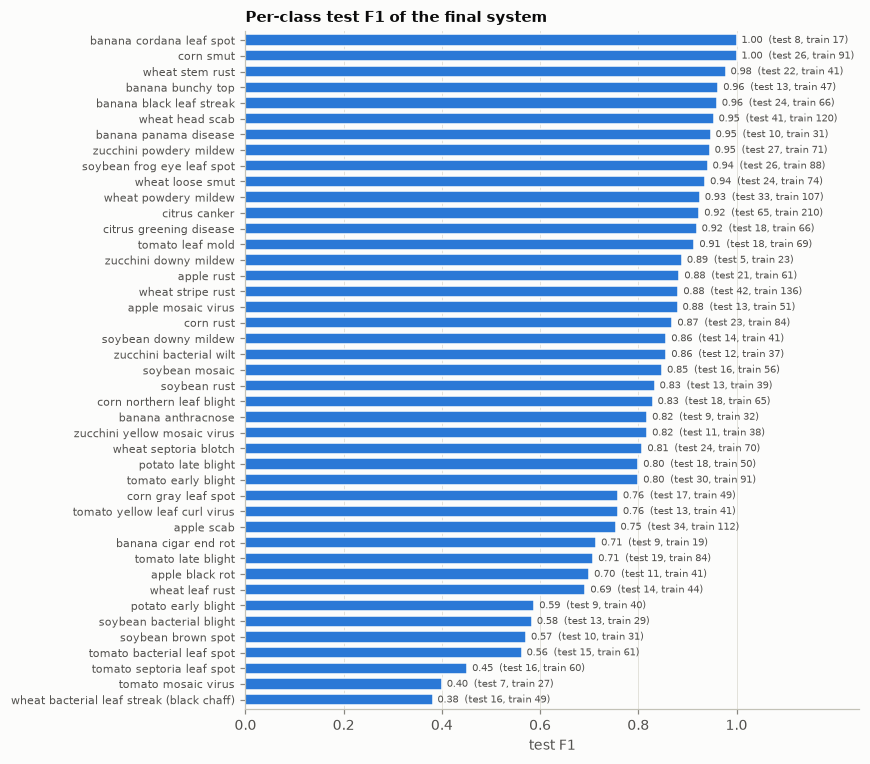

In [15]:
pc = REP["final"]["per_class"].copy()
pc["train_images"] = counts.loc[pc["class"], "train"].to_numpy()
display(pc.sort_values("f1"))
R.fig_perclass(P); plt.show()

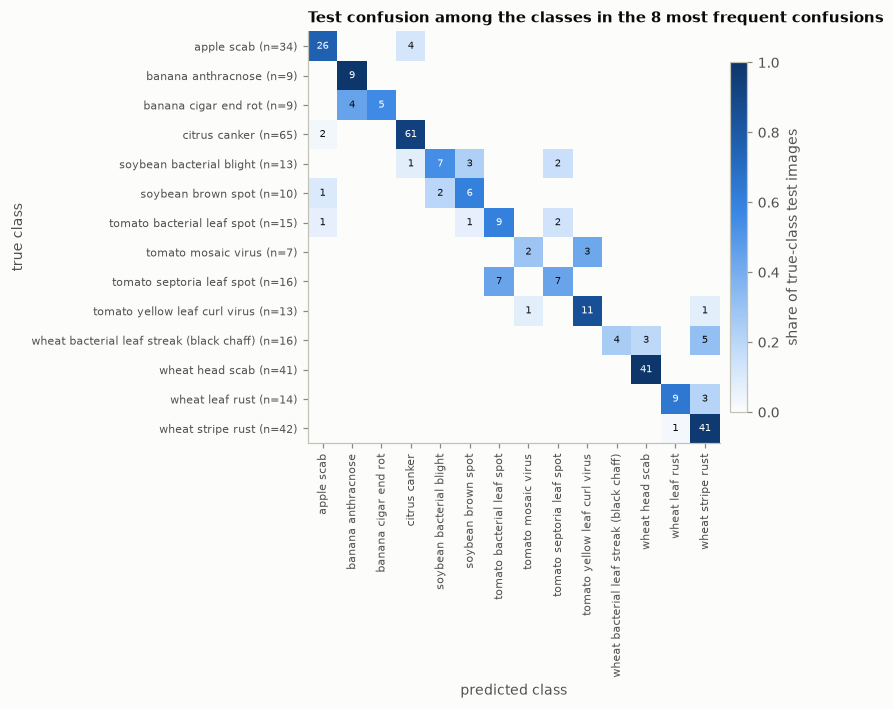

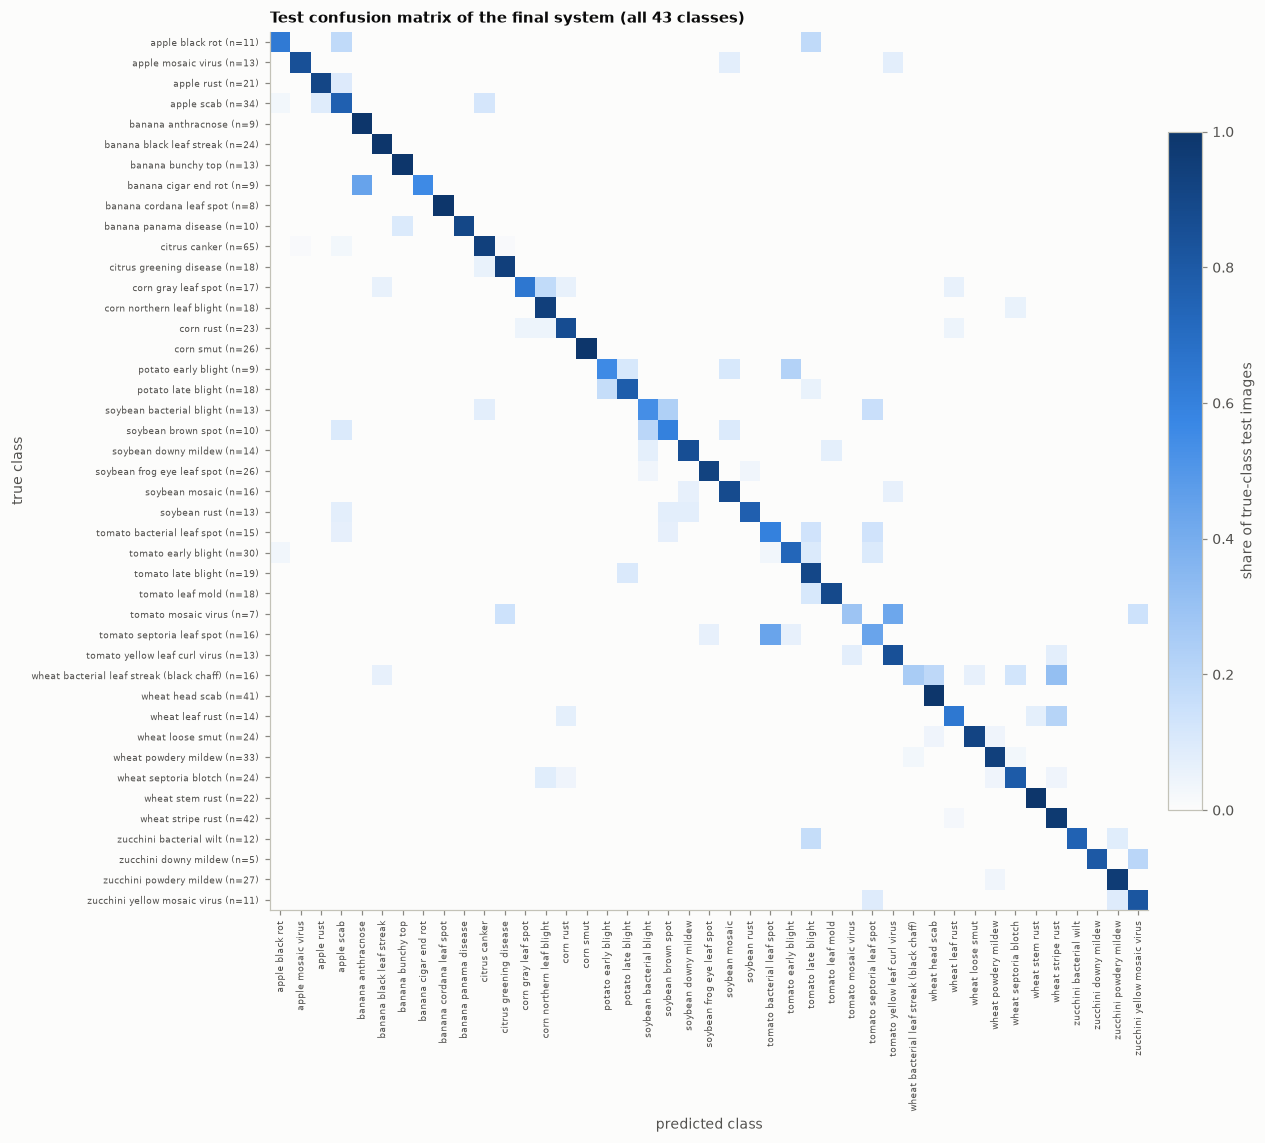

In [16]:
R.fig_confusion(P, full=False); plt.show()
R.fig_confusion(P, full=True); plt.show()

## 9. Error analysis

In [17]:
conf = REP["final"]["confusion"]; off = conf.copy(); np.fill_diagonal(off, 0)
top = [(CLASSES[i], CLASSES[j], off[i, j]) for i, j in zip(*np.unravel_index(np.argsort(-off.ravel())[:10], off.shape))]
display(pd.DataFrame(top, columns=["true", "predicted as", "test images"]))
same_host = np.mean([MAN.drop_duplicates("class_name").set_index("class_name").loc[t, "host"] ==
                     MAN.drop_duplicates("class_name").set_index("class_name").loc[p, "host"] for t, p, _ in top])
pr = REP["predictions"]; wrong = pr[pr.true != pr.pred]
host = MAN.drop_duplicates("class_id").set_index("class_id")["host"]
print(f"{len(wrong)} test errors; {np.mean(host[wrong.true].to_numpy() == host[wrong.pred].to_numpy()):.0%} of them predict "
      f"a disease of the correct host; {same_host:.0%} of the top-10 confusions are within one host")
from scipy.stats import spearmanr
rho = spearmanr(pc.train_images, pc.f1)
print(f"per-class F1 vs training images: Spearman rho = {rho.statistic:.2f} (p = {rho.pvalue:.3f})")

,true,predicted as,test images
0,tomato septoria leaf spot,tomato bacterial leaf spot,7
1,wheat bacterial leaf streak (black chaff),wheat stripe rust,5
2,apple scab,citrus canker,4
3,banana cigar end rot,banana anthracnose,4
4,wheat bacterial leaf streak (black chaff),wheat head scab,3
5,soybean bacterial blight,soybean brown spot,3
6,wheat leaf rust,wheat stripe rust,3
7,tomato mosaic virus,tomato yellow leaf curl virus,3
8,potato late blight,potato early blight,3
9,apple scab,apple rust,3


131 test errors; 66% of them predict a disease of the correct host; 90% of the top-10 confusions are within one host
per-class F1 vs training images: Spearman rho = 0.29 (p = 0.060)


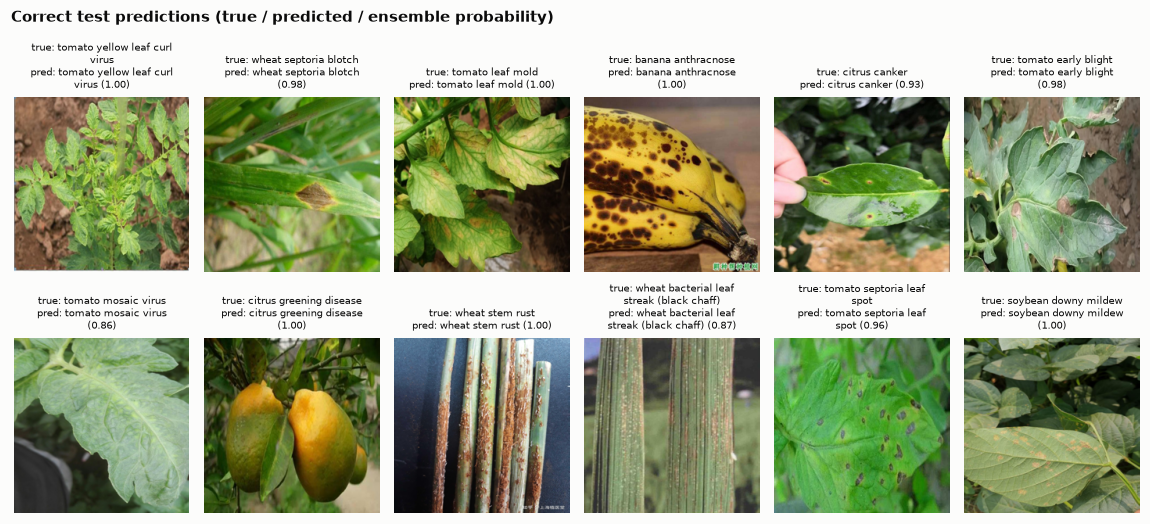

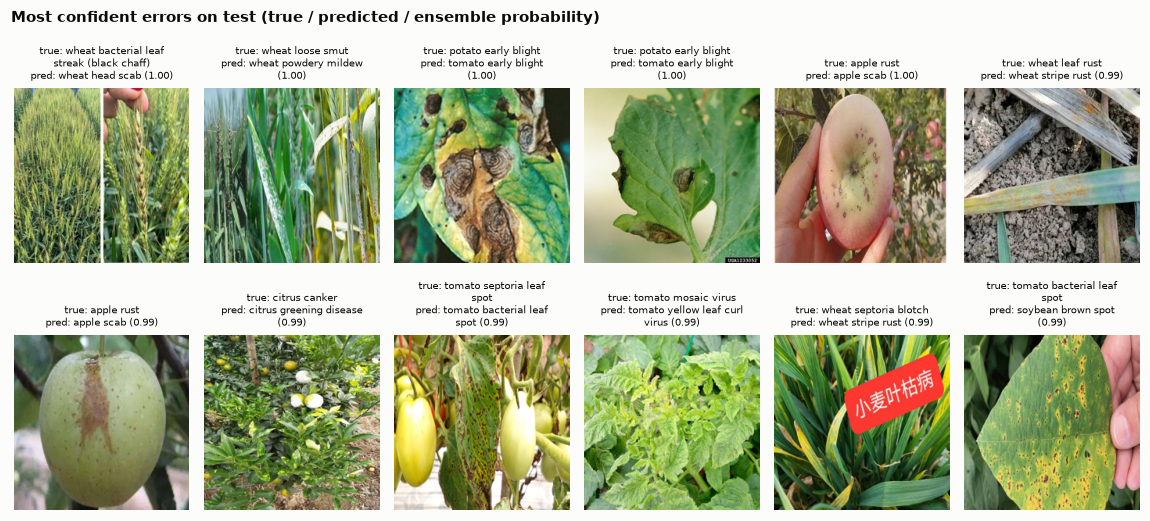

In [18]:
R.fig_gallery(P, "success"); plt.show()
R.fig_gallery(P, "failure"); plt.show()

**Reading the errors.**
- Two thirds of the errors — and 9 of the 10 most frequent confusions — stay **within the correct host** and confuse look-alike diseases: wheat rusts (leaf ↔ stripe), tomato
  septoria ↔ bacterial leaf spot, soybean bacterial blight ↔ brown spot, banana cigar-end rot ↔ anthracnose, tomato
  mosaic ↔ yellow-leaf-curl virus. These pairs differ in lesion shape and margin at a scale that a 224-pixel squashed
  whole-plant photo can blur away.
- **Same disease, other host**: potato early blight is predicted as tomato early blight with probability 1.0 — the
  symptom is identical and the photo gives little host evidence; the audit already found such photos labelled both ways.
- **Wheat bacterial leaf streak (black chaff)** is the weakest class (recall 0.25): its field photos of whole ears look
  like head scab or stripe rust.
- Some confident errors are **label or content problems** rather than model errors — e.g. a test photo labelled
  *wheat septoria blotch* carrying a red banner that reads “小麦叶枯病” (wheat leaf blight), and several web images with
  watermarks or overlaid text.
- Per-class F1 is only weakly related to the number of training images (Spearman ρ = 0.29, p = 0.06), so the hard
  classes are hard mainly because of visual similarity, not only because they are small.

## 10. Inference demonstration (RGB image → class)

The three final checkpoints are loaded (locally if present, otherwise from the public Hugging Face repo) and checked to
reproduce the stored test predictions; then any image file can be classified.

checkpoints reproduce stored predictions on 96 test images: argmax agreement 1.000, max |prob diff| 1.1e-03


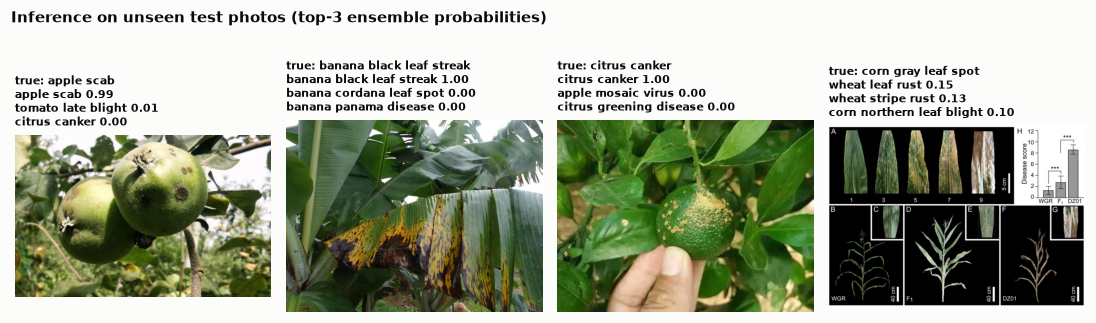

In [19]:
cfg = X.run_config(P.runs, SEL["final_config"])
models = [I.load_model(cfg, I.checkpoint_path(f"{SEL['final_config']}_s{s}", P.checkpoints), len(CLASSES), DEVICE) for s in X.SEEDS]
test_rows = MAN[MAN.partition == "test"].reset_index(drop=True)
chk = test_rows.sample(96, random_state=0)
probs = I.predict_proba(models, I.load_images([P.data_root / p for p in chk.path], cfg.cache_size), cfg.input_size, DEVICE)
stored = X.final_probs(P.runs, SEL, "test")[chk.index.tolist()]
print(f"checkpoints reproduce stored predictions on {len(chk)} test images: argmax agreement "
      f"{(probs.argmax(1) == stored.argmax(1)).float().mean():.3f}, max |prob diff| {(probs - stored).abs().max():.1e}")

def classify(path, k=3):
    p = I.predict_proba(models, I.load_images([pathlib.Path(path)], cfg.cache_size), cfg.input_size, DEVICE)[0]
    top = p.topk(k)
    return [(CLASSES[i], float(v)) for v, i in zip(top.values, top.indices)]

demo = test_rows.groupby("host").sample(1, random_state=3).head(4)
fig, axes = plt.subplots(1, 4, figsize=(10, 3.6))
for ax, r in zip(axes, demo.itertuples()):
    preds = classify(P.data_root / r.path)
    ax.imshow(PIL.Image.open(P.data_root / r.path).convert("RGB")); ax.axis("off")
    ax.set_title(f"true: {r.class_name}\n" + "\n".join(f"{c} {v:.2f}" for c, v in preds), fontsize=7, loc="left")
fig.suptitle("Inference on unseen test photos (top-3 ensemble probabilities)", x=0.01, ha="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

The fourth test "photo" is in fact a multi-panel figure from a scientific article (bar chart, scale bars, whole
plants) — another example of web-sourced content in the dataset. The ensemble is unsure (top probability 0.15) rather
than confidently wrong, which is the desirable behaviour for such an input.

## 11. Reproducibility record

In [20]:
runs = X.load_runs(P.runs)
display(pd.Series({
    "dataset": "PlantSeg v7, Zenodo 17719108, plantseg.zip md5 " + D.ZENODO_MD5,
    "manifest": "results/data/manifest.csv (4,349 images; 424 excluded; 3,925 used)",
    "seeds": "0, 1, 2 for every configuration (torch, numpy, shuffling and augmentation generators)",
    "checkpoint rule": "epoch with best validation macro-F1 (30 epochs, 50 for one stage-1 config)",
    "selection rule": "highest validation macro-F1 among configs and top-5 ensembles; frozen in results/summary/selection.json",
    "pretrained weights": "torchvision IMAGENET1K_V1 (ResNet-18, EfficientNet-B0, ConvNeXt-T/S), IMAGENET1K_V2 (ResNet-50, MobileNetV3-L)",
    "hardware (reported runs)": "1x NVIDIA L4 24 GB, 8 vCPU, 4 runs sharing the GPU",
    "total recorded training time": f"{runs.train_seconds.sum() / 3600:.1f} GPU-hours over {len(runs)} runs (under 4-way sharing)",
    "final checkpoints": f"Hugging Face {I.HF_REPO_ID} (checkpoints/{SEL['final_config']}_s{{0,1,2}}.pt)",
}).to_frame("value"))
display(runs.groupby("name").train_seconds.mean().rename("mean seconds per run").to_frame().join(
    pd.Series(labels, name="config")).sort_values("mean seconds per run"))

,value
dataset,"PlantSeg v7, Zenodo 17719108, plantseg.zip md5..."
manifest,"results/data/manifest.csv (4,349 images; 424 e..."
seeds,"0, 1, 2 for every configuration (torch, numpy,..."
checkpoint rule,epoch with best validation macro-F1 (30 epochs...
selection rule,highest validation macro-F1 among configs and ...
pretrained weights,"torchvision IMAGENET1K_V1 (ResNet-18, Efficien..."
hardware (reported runs),"1x NVIDIA L4 24 GB, 8 vCPU, 4 runs sharing the..."
total recorded training time,12.5 GPU-hours over 66 runs (under 4-way sharing)
final checkpoints,Hugging Face alexjiang04/plantseg-aip-checkpoi...


,mean seconds per run,config
name,,
E0_frozen,113.0000,resnet18 · frozen
E1_finetune,285.3333,resnet18 · fine-tune
E2_finetune_cw,303.0000,resnet18 · fine-tune · class-weighted
E3_finetune_aug,308.6667,resnet18 · fine-tune · aug
S1_aug_lrb3e-5,312.0000,resnet18 · fine-tune · aug · lr-bb 3e-05
S1_aug_lrb3e-4,312.0000,resnet18 · fine-tune · aug · lr-bb 0.0003
S1_aug_cw,312.6667,resnet18 · fine-tune · aug · class-weighted
S1_aug_ls0.1,314.6667,resnet18 · fine-tune · aug · LS 0.1
S1_aug_mnv3l,334.6667,mobilenet-v3-large · fine-tune · aug


**Regenerating everything outside the notebook:** `python scripts/01_prepare_data.py` → `02_sweep.py` (run several
copies to share one GPU) → `03_select.py` → `04_test_report.py` → `05_figures.py`. The notebook calls the same
functions in `cw2/`.

**Acknowledgements.** Images and labels: PlantSeg (Wei et al., 2025, 2026), images licensed CC BY-NC / CC0 by their
original web sources (per-image source URL and licence in `results/data/manifest.csv`). Pretrained weights: torchvision.
PyTorch transfer-learning tutorial (Chilamkurthy, 2025) as the starting point.